# Project 2: Evolutionary Algorithms
Machine Learning T-504-ITML 

Group: Dagur Smári (dagurss24@ru.is) and Kamil Michal (kamil24@ru.is)

## The Setup

In [1]:
import random
import numpy as np
seed = 42240 #last 5 digit of smallest student number
random.seed(seed)
np.random.seed(seed)
import matplotlib.pyplot as plt
import pandas as pd

---
## Task 1: 6-bit Representation of Integers

In [2]:
## Functions to go from phenome type to genotype and back
def geno_to_pheno(individuals):
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

### 1.1 Initialization function

In [3]:
def initialization_population(pop_size):
    
    population = []
    for i in range(pop_size):
        digit = random.randint(0, 63)
        population.append(digit)
    return pheno_to_geno(population)

**Subtask: generate 4 individuals**

In [4]:
test_population = initialization_population(4)
print("Individuals:", test_population)
print("As integers:", geno_to_pheno(test_population))
print("Output type: a", type(test_population).__name__, "of", type(test_population[0]).__name__ + "s",
      "(each of length", len(test_population[0]), ")")

Individuals: [[0, 0, 0, 1, 0, 0], [1, 1, 1, 0, 0, 0], [0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 0, 1]]
As integers: [4, 56, 28, 33]
Output type: a list of lists (each of length 6 )


### 1.2 Fitness function

In [5]:
def fitness(individuals):

    # Takes in geno values [x, x, x, x, x, x]
    x_values = geno_to_pheno(individuals)
    result = []
    
    for x in x_values:
        
        if x >= 32:
            y = x - 64
        else:
            y = x
            
        fitness_value = (
            -0.00008333 * pow(y, 6)
            - 0.001 * pow(y, 5)
            + 0.09375 * pow(y, 4)
            + 1.16667 * pow(y, 3)
            - 19.53125 * pow(y, 2)
            - 234.375 * y
            + 8350
        )

        result.append(fitness_value)    

    #return pheno values
    return result

**Subtask: Check for individual = [[0, 1, 0, 1, 0, 1]]**

In [6]:
individual = [[0, 1, 0, 1, 0, 1]]
print("Expected fitness value: 12620.97")
print("Fitness value: " + str(round(fitness(individual)[0], 2)))

Expected fitness value: 12620.97
Fitness value: 12620.98


**Subtask: Fitness landscape and min/max x-values**

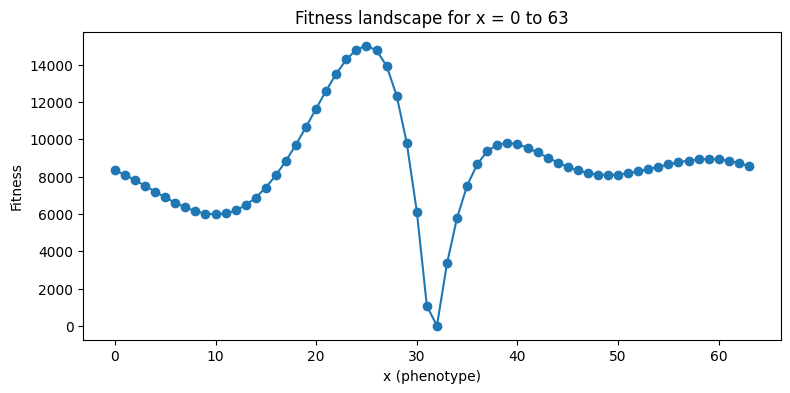

Max fitness: 15024.04 at x = 25 or [0, 1, 1, 0, 0, 1]
Min fitness: 4.08 at x = 32 or [1, 0, 0, 0, 0, 0]


In [7]:
# Plot of the landscape
x_values = list(range(64))
fitness_values = fitness(pheno_to_geno(x_values))

plt.figure(figsize=(9, 4))
plt.plot(x_values, fitness_values, marker="o")
plt.xlabel("x (phenotype)")
plt.ylabel("Fitness")
plt.title("Fitness landscape for x = 0 to 63")
plt.show()

# Which x gives min and max fitness
x_max = x_values[fitness_values.index(max(fitness_values))]
x_min = x_values[fitness_values.index(min(fitness_values))]

print("Max fitness:", round(max(fitness_values), 2), "at x =", x_max, "or", pheno_to_geno([x_max])[0])
print("Min fitness:", round(min(fitness_values), 2), "at x =", x_min, "or", pheno_to_geno([x_min])[0])

### 1.3 Parent selection function

In [8]:
def parent_selection(individuals, fitness_values):

    total_fitness = sum(fitness_values)
    fitness_val_probabilities = []

    for i in range(len(fitness_values)):
        fitness_val_probabilities.append(fitness_values[i] / total_fitness)

    selected = np.random.choice(len(individuals),size=len(individuals),replace=True,p=fitness_val_probabilities)

    parents = []
    for i in selected:
        parents.append(list(individuals[i]))
    return parents

## Windowing needed for bonus

**Subtask: Testing on four individuals**

In [9]:
# Use x_values, fitness_values, x_min and x_max from fitness cell

# the 2 x values with fitness closest to the middle of the fitness range
middle = (min(fitness_values) + max(fitness_values)) / 2
closest = sorted(x_values, key=lambda x: abs(fitness_values[x] - middle))[:2]

test_x = [x_min, x_max] + closest
test_individuals = pheno_to_geno(test_x)
test_fitness = fitness(test_individuals)

for x, g, f in zip(test_x, test_individuals, test_fitness):
    print(f"x = {x} (genotype = {g}) fitness = {round(f, 2)} probability = {round((f / sum(test_fitness)), 4)}")

parents = parent_selection(test_individuals, test_fitness)
print("------------------------")
print("Parents: ", parents)
print("As x: ", geno_to_pheno(parents))

x = 32 (genotype = [1, 0, 0, 0, 0, 0]) fitness = 4.08 probability = 0.0001
x = 25 (genotype = [0, 1, 1, 0, 0, 1]) fitness = 15024.04 probability = 0.4998
x = 3 (genotype = [0, 0, 0, 0, 1, 1]) fitness = 7509.88 probability = 0.2499
x = 35 (genotype = [1, 0, 0, 0, 1, 1]) fitness = 7519.29 probability = 0.2502
------------------------
Parents:  [[0, 0, 0, 0, 1, 1], [0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1]]
As x:  [3, 25, 25, 25]


### 1.4 Crossover

In [10]:
def one_point_crossover(parents, crossover_prob):
     
    off_spring = []

    for i in range(0, len(parents), 2):

        if i == len(parents) - 1:
            off_spring.append(parents[i].copy())
            break

        number = random.random()   
        if number > crossover_prob:
            off_spring.append(parents[i].copy())
            off_spring.append(parents[i+1].copy())
            continue

        crossover_point = random.randint(1, len(parents[i]) - 1)

        offspring1 = parents[i]
        offspring2 = parents[i+1]

        new_offspring1 = offspring1[:crossover_point] + offspring2[crossover_point:]
        new_offspring2 = offspring2[:crossover_point] + offspring1[crossover_point:]

        off_spring.append(new_offspring1)
        off_spring.append(new_offspring2)

    return off_spring

**Subtask: Crossover of two parents**

In [11]:
test_parents = [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]
children = one_point_crossover(test_parents, 1.0)

print("Parents:  ", test_parents)
print("Offspring:", children)
cut = children[0].index(1)
print("Cut point: after gene", cut)
print("With pc = 0:", one_point_crossover(test_parents, 0.0))

Parents:   [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]
Offspring: [[0, 1, 1, 1, 1, 1], [1, 0, 0, 0, 0, 0]]
Cut point: after gene 1
With pc = 0: [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]


### 1.5 Mutation

In [12]:
def mutation(individuals, mutation_prob):
    
    mutated = []

    for i in individuals:
        new_individual = i.copy()

        for j in range(len(new_individual)):
            number = random.random()
            if number <= mutation_prob:
                # flip the gene
                new_individual[j] = 1 - new_individual[j]

        mutated.append(new_individual)

    return mutated

**Subtask: mutation of one individual**

In [13]:
individual = [[0, 1, 0, 1, 0, 1]]
mutated_02 = mutation(individual, 0.2)[0]
mutated_09 = mutation(individual, 0.9)[0]

# count how many genes were flipped
flips_02 = 0
flips_09 = 0
for j in range(len(individual[0])):
    if individual[0][j] != mutated_02[j]:
        flips_02 += 1
    if individual[0][j] != mutated_09[j]:
        flips_09 += 1

print("Original individual:", individual[0])
print("-----------")
print("After mutation with pm = 0.2:", mutated_02, "->", flips_02, "genes flipped (expected 6 x 0.2 = 1.2)")
print("After mutation with pm = 0.9:", mutated_09, "->", flips_09, "genes flipped (expected 6 x 0.9 = 5.4)")

Original individual: [0, 1, 0, 1, 0, 1]
-----------
After mutation with pm = 0.2: [1, 1, 0, 0, 0, 0] -> 3 genes flipped (expected 6 x 0.2 = 1.2)
After mutation with pm = 0.9: [1, 0, 1, 0, 1, 1] -> 5 genes flipped (expected 6 x 0.9 = 5.4)


Comment on whether the number of bit flips is expected

(maybe do more/better tests)

### 1.6 Survivor selection

In [14]:
def survivor_selection(individuals, offspring, fitness_individuals, fitness_offspring):
    survivors = []

    all_individuals = individuals + offspring
    all_fitness = list(fitness_individuals) + list(fitness_offspring)

    # sort positions from highest to lowest
    for k in range(len(individuals)):
        # find the fittest one left, move it to the survivors
        best = all_fitness.index(max(all_fitness))
        survivors.append(all_individuals.pop(best))
        all_fitness.pop(best)

    return survivors

**Subtask: Test fitter individual**

In [15]:
parent = [[0, 1, 0, 1, 0, 1]]   # x = 21
child = [[0, 1, 1, 0, 0, 1]]     # x = 25
survivor = survivor_selection(parent, child, fitness(parent), fitness(child))

print("Parent:", parent[0], "Fitness =", round(fitness(parent)[0], 2))
print("Offspring:", child[0], "Fitness =", round(fitness(child)[0], 2))
print("------------")
print("Survivor:", survivor[0], "Fitness =", round(fitness(survivor)[0], 2))

Parent: [0, 1, 0, 1, 0, 1] Fitness = 12620.98
Offspring: [0, 1, 1, 0, 0, 1] Fitness = 15024.04
------------
Survivor: [0, 1, 1, 0, 0, 1] Fitness = 15024.04


In [16]:
# Case 2: the population individual is fitter
parent = [[0, 1, 1, 0, 0, 1]]    # x = 25
child = [[1, 0, 0, 0, 0, 0]]     # x = 32
survivor = survivor_selection(parent, child, fitness(parent), fitness(child))

print("Parent:", parent[0], "Fitness =", round(fitness(parent)[0], 2))
print("Offspring:", child[0], "Fitness =", round(fitness(child)[0], 2))
print("------------")
print("Survivor:", survivor[0], "Fitness =", round(fitness(survivor)[0], 2))
print()

# Population size stays the same: the 4 test individuals from 1.3 and the 4 parents from 1.3 as offspring
new_population = survivor_selection(test_individuals, parents, fitness(test_individuals), fitness(parents))
print("Population:", geno_to_pheno(test_individuals), "size", len(test_individuals))
print("Offspring: ", geno_to_pheno(parents), "size", len(parents))
print("Survivors: ", geno_to_pheno(new_population), "size", len(new_population))

Parent: [0, 1, 1, 0, 0, 1] Fitness = 15024.04
Offspring: [1, 0, 0, 0, 0, 0] Fitness = 4.08
------------
Survivor: [0, 1, 1, 0, 0, 1] Fitness = 15024.04

Population: [32, 25, 3, 35] size 4
Offspring:  [3, 25, 25, 25] size 4
Survivors:  [25, 25, 25, 25] size 4


### 1.7 Complete version of SGA (Loop)

In [17]:
def sga(pop_size, n_iterations, crossover_prob, mutation_prob,
        init_function=initialization_population, fitness_function=fitness,
        crossover_function=one_point_crossover, mutation_function=mutation,
        print_every=1):

    # start with random population and its fitness
    population = init_function(pop_size)
    population_fitness = fitness_function(population)

    # save the history (to show improvement)
    best_history = [max(population_fitness)]
    average_history = [sum(population_fitness) / pop_size]

    if print_every > 0:
        print(f"Iteration 0: average fitness = {round(average_history[-1], 2)}, best fitness = {round(best_history[-1], 2)}")

    for iteration in range(1, n_iterations + 1):

        # repeated steps in every iteration
        parents = parent_selection(population, population_fitness)
        offspring = crossover_function(parents, crossover_prob)
        offspring = mutation_function(offspring, mutation_prob)
        offspring_fitness = fitness_function(offspring)

        population = survivor_selection(population, offspring, population_fitness, offspring_fitness)
        population_fitness = fitness_function(population)

        # save and show the average and best fitness of this iteration
        best_history.append(max(population_fitness))
        average_history.append(sum(population_fitness) / pop_size)

        # print every # number of lines (for later tasks, can change to every 100 lines for example)
        if print_every > 0 and iteration % print_every == 0:
            print(f"Iteration {iteration}: average fitness = {round(average_history[-1], 2)}, best fitness = {round(best_history[-1], 2)}")

    return population, population_fitness, best_history, average_history

**Subtask: Display best & average fitness**

Iteration 0: average fitness = 7768.79, best fitness = 9549.33
Iteration 1: average fitness = 9361.16, best fitness = 11650.24
Iteration 2: average fitness = 9722.36, best fitness = 11650.24
Iteration 3: average fitness = 9759.42, best fitness = 11650.24
Iteration 4: average fitness = 10104.51, best fitness = 12620.98
Iteration 5: average fitness = 10959.15, best fitness = 15024.04
Iteration 6: average fitness = 12789.95, best fitness = 15024.04
Iteration 7: average fitness = 13321.47, best fitness = 15024.04
Iteration 8: average fitness = 13693.39, best fitness = 15024.04
Iteration 9: average fitness = 14545.92, best fitness = 15024.04
Iteration 10: average fitness = 15024.04, best fitness = 15024.04
Iteration 11: average fitness = 15024.04, best fitness = 15024.04
Iteration 12: average fitness = 15024.04, best fitness = 15024.04
Iteration 13: average fitness = 15024.04, best fitness = 15024.04
Iteration 14: average fitness = 15024.04, best fitness = 15024.04
Iteration 15: average fit

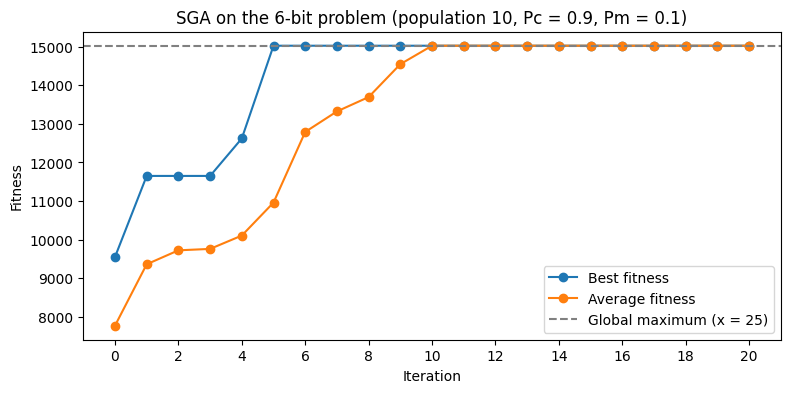

In [18]:
population, population_fitness, best_history, average_history = sga(10, 20, 0.9, 0.1)

print("------------------------")
print("Final population (x):", geno_to_pheno(population))

#Simple plot
plt.figure(figsize=(9, 4))
plt.plot(best_history, marker="o", label="Best fitness")
plt.plot(average_history, marker="o", label="Average fitness")
plt.axhline(max(fitness_values), color="grey", linestyle="--", label="Global maximum (x = 25)")
plt.xticks(range(0, len(best_history), 2))
plt.xlabel("Iteration")
plt.ylabel("Fitness")
plt.title("SGA on the 6-bit problem (population 10, Pc = 0.9, Pm = 0.1)")
plt.legend()
plt.show()

In [19]:
# check if the best and average fitness ever went down
best_never_decreases = True
average_never_decreases = True
for i in range(1, len(best_history)):
    if best_history[i] < best_history[i - 1]:
        best_never_decreases = False
    if average_history[i] < average_history[i - 1] - 1e-9:   # tiny tolerance for rounding
        average_never_decreases = False

print("Best fitness never decreases:   ", best_never_decreases)
print("Average fitness never decreases:", average_never_decreases)

Best fitness never decreases:    True
Average fitness never decreases: True


### 1.8 Testing SGA

In [20]:
pop_sizes = [4, 6, 10, 20, 50]
iteration_counts = [1, 5, 10, 20, 50]
n_runs = 30   # each combination is run 30 times, one run alone is too random

rows = []

for pop_size in pop_sizes:
    for n_iterations in iteration_counts:

        best_total = 0
        average_total = 0
        found_max = 0

        for run in range(n_runs):
            population, population_fitness, best_history, average_history = sga(pop_size, n_iterations, 0.9, 0.1, print_every=0)

            best_total += max(population_fitness)
            average_total += sum(population_fitness) / pop_size
            if 25 in geno_to_pheno(population):
                found_max += 1

        rows.append([pop_size, n_iterations, best_total / n_runs, average_total / n_runs, 100 * found_max / n_runs])

results = pd.DataFrame(rows, columns=["Population size", "Iterations", "Mean best", "Mean average", "% found x = 25"])

print("Mean best fitness (rows: population size, columns: iterations)")
print(results.pivot(index="Population size", columns="Iterations", values="Mean best").round(1))
print()
print("Mean average fitness")
print(results.pivot(index="Population size", columns="Iterations", values="Mean average").round(1))
print()
print("% of runs that found the global maximum x = 25")
print(results.pivot(index="Population size", columns="Iterations", values="% found x = 25").round(0))

Mean best fitness (rows: population size, columns: iterations)
Iterations            1        5        10       20       50
Population size                                             
4                11221.4  13913.1  12945.9  14107.0  14301.0
6                13013.3  14375.9  14836.6  14515.4  14900.9
10               14200.4  14552.8  14984.4  14974.8  14925.5
20               14611.5  14983.2  15017.2  15024.0  15024.0
50               14968.1  15024.0  15024.0  15024.0  15024.0

Mean average fitness
Iterations            1        5        10       20       50
Population size                                             
4                10131.4  13173.2  12871.7  13987.9  14301.0
6                10462.7  14098.8  14665.5  14514.9  14894.3
10               10800.8  14177.1  14872.5  14971.4  14925.5
20               10731.7  14679.3  14981.5  15021.3  15024.0
50               10784.7  14693.0  15022.4  15024.0  15024.0

% of runs that found the global maximum x = 25
Iterations   

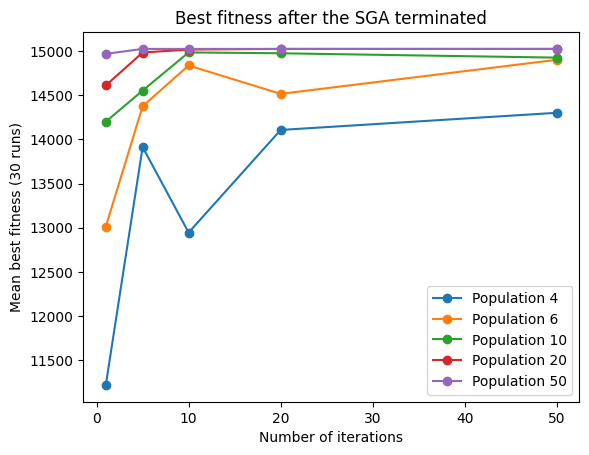

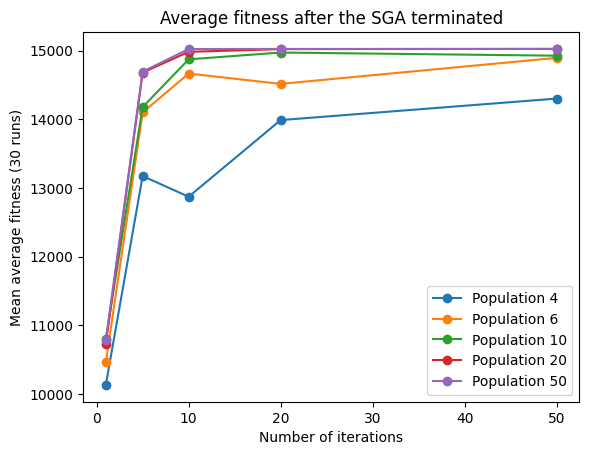

In [21]:
# Plots
for pop_size in pop_sizes:
    rows_for_size = results[results["Population size"] == pop_size]
    plt.plot(rows_for_size["Iterations"], rows_for_size["Mean best"], marker="o", label=f"Population {pop_size}")
plt.xlabel("Number of iterations")
plt.ylabel("Mean best fitness (30 runs)")
plt.title("Best fitness after the SGA terminated")
plt.legend()
plt.show()

for pop_size in pop_sizes:
    rows_for_size = results[results["Population size"] == pop_size]
    plt.plot(rows_for_size["Iterations"], rows_for_size["Mean average"], marker="o", label=f"Population {pop_size}")
plt.xlabel("Number of iterations")
plt.ylabel("Mean average fitness (30 runs)")
plt.title("Average fitness after the SGA terminated")
plt.legend()
plt.show()

### Extra checks for Task 1
These use random numbers, so they are placed last and do not change any of the results above.

In [22]:
# 1.5: repeat the mutation many times to see the average number of flips
for pm in [0.2, 0.9]:
    total_flips = 0
    for r in range(10000):
        mutated = mutation(individual, pm)
        for j in range(len(individual[0])):
            if individual[0][j] != mutated[0][j]:
                total_flips += 1
    print(f"pm = {pm}: average flips over 10000 mutations = {round(total_flips / 10000, 3)} (expected {round(6 * pm, 1)})")

pm = 0.2: average flips over 10000 mutations = 1.206 (expected 1.2)
pm = 0.9: average flips over 10000 mutations = 5.399 (expected 5.4)


In [23]:
# 1.8: where do the runs that miss x = 25 end up? (population 4 and 6, 50 iterations)
for pop_size in [4, 6]:
    end_points = []
    for run in range(n_runs):
        population, population_fitness, best_history, average_history = sga(pop_size, 50, 0.9, 0.1, print_every=0)
        best_x = geno_to_pheno(population)[population_fitness.index(max(population_fitness))]
        end_points.append(best_x)
    counts = {x: end_points.count(x) for x in sorted(set(end_points))}
    print(f"Population {pop_size}: best x at the end of the 30 runs -> {counts}")

Population 4: best x at the end of the 30 runs -> {23: 8, 24: 1, 25: 21}
Population 6: best x at the end of the 30 runs -> {23: 3, 25: 26, 26: 1}


In [24]:
# 1.8: x = 23 is a trap: every single bit flip gives a lower fitness
trap = pheno_to_geno([23])[0]
print("x = 23:", trap, "fitness =", round(fitness([trap])[0], 2))
for i in range(6):
    neighbour = trap.copy()
    neighbour[i] = 1 - neighbour[i]
    print(neighbour, "x =", geno_to_pheno([neighbour])[0], "fitness =", round(fitness([neighbour])[0], 2))

x = 23: [0, 1, 0, 1, 1, 1] fitness = 14285.14
[1, 1, 0, 1, 1, 1] x = 55 fitness = 8656.7
[0, 0, 0, 1, 1, 1] x = 7 fitness = 6350.99
[0, 1, 1, 1, 1, 1] x = 31 fitness = 1066.37
[0, 1, 0, 0, 1, 1] x = 19 fitness = 10669.44
[0, 1, 0, 1, 0, 1] x = 21 fitness = 12620.98
[0, 1, 0, 1, 1, 0] x = 22 fitness = 13523.25


---
## Task 2: Knapsack for ”data 1001” data set

### 2.1 Load the data set

In [25]:
data = pd.read_csv("data_1001.csv")

item_values = data["Value"].tolist()
item_weights = data["Weight"].tolist()

print("Size of the data set:", data.shape[0], "items and", data.shape[1], "columns")
print(data.describe().round(1))

Size of the data set: 1001 items and 2 columns
         Value    Weight
count   1001.0    1001.0
mean    5762.2   10134.0
std     5770.4    6386.1
min    -4299.0       1.0
25%      940.0    5245.0
50%     5819.0   10133.0
75%    10596.0   15012.0
max    17195.0  100000.0


**analizes of the data**

In [26]:
corr = data["Value"].corr(data["Weight"])
print(corr)

0.8835732958717434


I checked the correletion between the two variables, and we got around 0.88%. Which indicates that there is a strong linear relationship between the two items. Basically with higher value, weight seems to be also higher. 

In [27]:
# values
negative = 0
for v in item_values:
    if v < 0:
        negative += 1
print("Items with negative value:", negative, "| positive value:", len(item_values) - negative)
print("Sum of positive values (best possible fitness in Task 2):", sum(v for v in item_values if v > 0))

# the first item is an outlier
print("First item: value =", item_values[0], "weight =", item_weights[0])
print("Heaviest item apart from the first:", max(item_weights[1:]))

# relationship between value and weight
print("Correlation:", round(data["Value"].corr(data["Weight"]), 4))
print("Correlation without the first item:", round(data["Value"][1:].corr(data["Weight"][1:]), 4))

slope, intercept = np.polyfit(item_weights[1:], item_values[1:], 1)
print(f"Straight line fit (without the first item): value = {round(slope, 4)} * weight {round(intercept, 1)}")

Items with negative value: 199 | positive value: 802
Sum of positive values (best possible fitness in Task 2): 6231819
First item: value = 3300 weight = 100000
Heaviest item apart from the first: 19995
Correlation: 0.8836
Correlation without the first item: 0.9936
Straight line fit (without the first item): value = 1.0025 * weight -4305.0


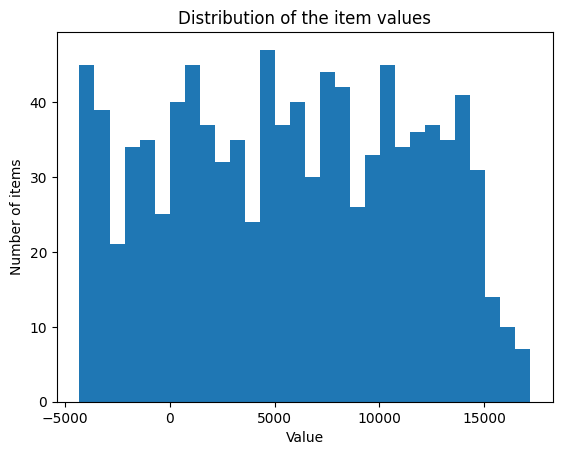

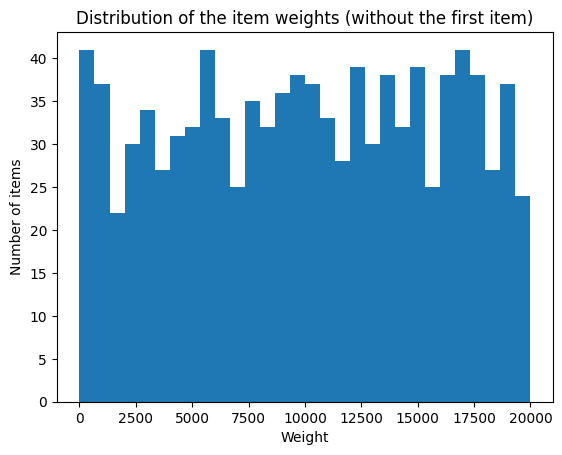

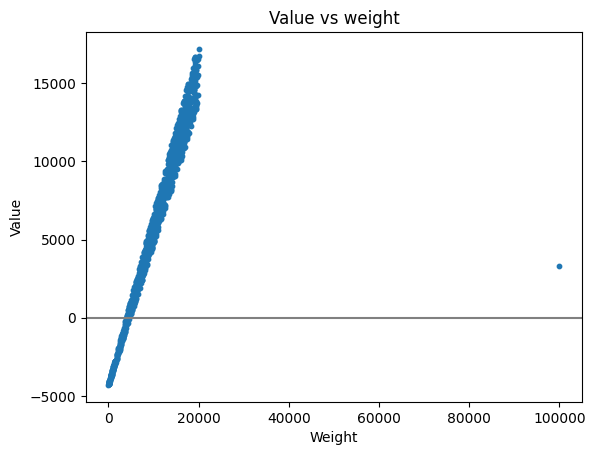

In [28]:
# Plots
plt.hist(item_values, bins=30)
plt.xlabel("Value")
plt.ylabel("Number of items")
plt.title("Distribution of the item values")
plt.show()

plt.hist(item_weights[1:], bins=30)
plt.xlabel("Weight")
plt.ylabel("Number of items")
plt.title("Distribution of the item weights (without the first item)")
plt.show()

plt.scatter(item_weights, item_values, s=10)
plt.axhline(0, color="grey")
plt.xlabel("Weight")
plt.ylabel("Value")
plt.title("Value vs weight")
plt.show()

### 2.2 New initialization function

In [29]:
def new_initialization_population(pop_size):
    
    population = []
    for i in range(pop_size):
        
        individual = []
        for j in range(len(item_values)):
            individual.append(random.randint(0, 1))
        population.append(individual)
        
    return population

**Check new initialization function**

In [ ]:
# 4 individuals
test_population = new_initialization_population(4)
for individual in test_population:
    print("Length:", len(individual), "| items selected:", sum(individual), "| first 10 genes:", individual[:10])

Length: 1001 | items selected: 524 | first 10 genes: [1, 1, 1, 1, 1, 0, 0, 1, 1, 0]
Length: 1001 | items selected: 510 | first 10 genes: [1, 1, 0, 0, 1, 1, 1, 0, 1, 0]
Length: 1001 | items selected: 486 | first 10 genes: [1, 0, 0, 1, 0, 0, 1, 0, 1, 1]
Length: 1001 | items selected: 495 | first 10 genes: [0, 0, 0, 0, 0, 1, 1, 0, 0, 0]


### 2.3 New fitness function

In [31]:
def new_fitness(individuals):

    results = []
    for individual in individuals:

        score = 0
        for i in range(len(individual)):
            if individual[i] == 1:
                score += item_values[i]
        results.append(score)
        
    return results

**Check for new fitness function**

In [ ]:
# Checks with answers we know from 2.1
n_items = len(item_values)
nothing = [0] * n_items
everything = [1] * n_items
only_first = [1] + [0] * (n_items - 1)

only_positive = []
for v in item_values:
    if v > 0:
        only_positive.append(1)
    else:
        only_positive.append(0)

print("Nothing selected: ", new_fitness([nothing])[0], "(expected 0)")
print("Everything selected: ", new_fitness([everything])[0], "(expected", sum(item_values), ")")
print("Only the first item: ", new_fitness([only_first])[0], "(expected", item_values[0], ")")
print("Only the positive items: ", new_fitness([only_positive])[0], "(expected 6231819, the best possible)")
print("Several at once: ", new_fitness([nothing, everything, only_first]))

### 4

In [32]:
population, population_fitness, best_history, average_history = sga(
    pop_size=30,
    n_iterations=1000,
    crossover_prob=0.9,
    mutation_prob=0.1,
    init_function=new_initialization_population,
    fitness_function=new_fitness,
    print_every=100
)

print("Final average fitness:", average_history[-1])
print("Final best fitness:", best_history[-1])

Iteration 0: average fitness = 2901584.63, best fitness = 3212016
Iteration 100: average fitness = 3809975.63, best fitness = 3862534
Iteration 200: average fitness = 3910463.97, best fitness = 3973884
Iteration 300: average fitness = 3982486.37, best fitness = 4035310
Iteration 400: average fitness = 4007828.87, best fitness = 4074153
Iteration 500: average fitness = 4035709.43, best fitness = 4090199
Iteration 600: average fitness = 4066537.9, best fitness = 4169569
Iteration 700: average fitness = 4086705.9, best fitness = 4169569
Iteration 800: average fitness = 4105335.3, best fitness = 4179318
Iteration 900: average fitness = 4123956.03, best fitness = 4184038
Iteration 1000: average fitness = 4138048.17, best fitness = 4217202
Final average fitness: 4138048.1666666665
Final best fitness: 4217202


### 5